In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import math

img = cv.imread("capt_baby_inter_1.png")
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

In [3]:
kernel_moyen = cv.getStructuringElement(cv.MORPH_ELLIPSE, (11, 11))
kernel_gros = cv.getStructuringElement(cv.MORPH_ELLIPSE, (21, 21))
#kernel_close = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))
kernel_petit = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
#proportion du kernbel possiblement a changer en fonction des résultats

#NOTE POUR LES MODIFS FUTURES: la taille d'un kernel MORPH_ELLIPSE doit être impaire


In [4]:
mask_green = cv.inRange(hsv, (40, 60, 50), (85, 170, 255))
mask_blue  = cv.inRange(hsv, (100, 150, 50), (130, 255, 255))
#les masques originaux pour les couleurs bleus et vertes

#Valeur pipette du terrain:
# claire (78.0, 96.9, 109.65) convertit
# sombre (72.5, 119.85, 43.35)

print(150 / 2)
print(36 * 255 / 100)
print(39 * 255 / 100)



75.0
91.8
99.45


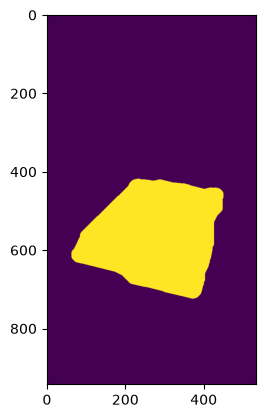

In [5]:
def masked_g_b(param_img):
    hsv = cv.cvtColor(param_img, cv.COLOR_BGR2HSV)
    mask_green_1 = cv.inRange(hsv, (41, 52, 43), (90, 140, 220))

    mask_green_2 = cv.inRange(hsv, (40, 65, 50), (85, 170, 255))
    #mask_blue  = cv.inRange(hsv, (100, 150, 50), (130, 255, 255))


    #masque a revoir, surtout pour le vert

    lower = np.array((41, 52, 43))
    upper = np.array((90, 140, 220))

    mask = cv.inRange(hsv, lower, upper)

    #ajout de la bordure temporaire pour éviter l'effet ventouse du bord sur la fermeture
    largeur_bordure = 60
    border = cv.copyMakeBorder(mask_green_1, largeur_bordure, largeur_bordure, largeur_bordure, largeur_bordure, borderType=cv.BORDER_REPLICATE)    

    opened = cv.morphologyEx(border, cv.MORPH_CLOSE, kernel_moyen, iterations=2)
    opened = cv.morphologyEx(opened, cv.MORPH_OPEN, kernel_petit, iterations=13)
    opened = cv.morphologyEx(opened, cv.MORPH_OPEN, kernel_gros, iterations=2)
    #opened = cv.morphologyEx(opened, cv.MORPH_OPEN, kernel_petit, iterations=8) L'originale, ca marchait bien
    opened = cv.morphologyEx(opened, cv.MORPH_CLOSE, kernel_gros, iterations=8)

    #suppression de la bordure temporaire
    opened = opened[largeur_bordure:opened.shape[0] - largeur_bordure,
                    largeur_bordure:opened.shape[1] - largeur_bordure]
    
    # le paramètre border_type permet de ne pas avoir l'effet vantouse du masque vers le bord quand celui ci s'en approche
    return opened

img_new = cv.imread("image_debugg/tempo_tre_tempo.png")
plt.imshow(masked_g_b(img_new))
#plt.imshow(masked_g_b(img_new))

Recherche des contours par rapport au masque réalisé précédement

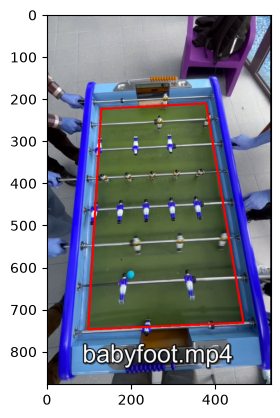

In [6]:
def apply_rectangular_contour(img):
    test_forme = masked_g_b(img)

    contours, _ = cv.findContours(test_forme, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    #cnt = contours[0]
    cnt = max(contours, key=cv.contourArea)
    pre_hull = cv.convexHull(cnt)
    if len(pre_hull) != 0:
        approx = cv.approxPolyN(pre_hull, 4,True)
        cv.drawContours(img, approx, -1, (255,0,0), 3)

    return img

img_conto = cv.imread("image_debugg/tres_tempo.png")
plt.imshow(apply_rectangular_contour(img_conto))


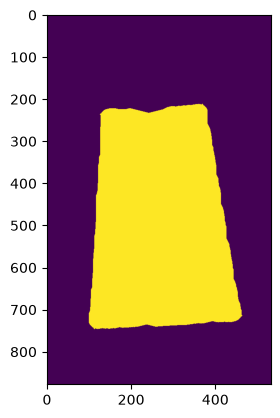

In [7]:
def apply_rectangular_contour_masque(img):
    test_forme = masked_g_b(img)

    contours, _ = cv.findContours(test_forme, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    cnt = contours[0]
    approx = cv.approxPolyDP(cv.convexHull(cnt), 0.01 * cv.arcLength(cnt, True), True)

    cv.drawContours(test_forme, approx, -1, (255,0,0), 3)
    (x, y), enculer = cv.minEnclosingCircle(cnt)

    return test_forme

img_conto = cv.imread("image_debugg/tres_tempo.png")        
plt.imshow(apply_rectangular_contour_masque(img_conto))

In [8]:
def display_lines(img):
    img_conto = img.copy()

    test_forme = apply_rectangular_contour_masque(img_conto)

    edges = cv.Canny(test_forme, 150, 500)
    lines = cv.HoughLines(edges, 1, np.pi / 360, 45, None, 0, 0)
    #1 --> alignement des piuxels
    #2 grossiérté de l'angle
    #3 seuil de la netteté des droites
    for rho, theta in lines[:, 0]:
        a = math.cos(theta)
        b = math.sin(theta)
        x0 = a * rho
        y0 = b * rho
        pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
        pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
        cv.line(img_conto, pt1, pt2, (255,0,0), 3, cv.LINE_AA)

    return img_conto

Application des filtres sur la vidéo

In [9]:
vid = cv.VideoCapture("Data/babyfoot3.mp4")      # chemin de fichier, ou 0 pour la webcam

while True:
    check, frame = vid.read()               # ok = False en fin de vidéo ou en cas d'erreur
    if not check:
        break
    scale_down = 0.50
    
    #frame = cv.resize(frame, None, fx=scale_down, fy=scale_down, interpolation=cv.INTER_LINEAR)
    #pour les vidéos de Ryan, la ligne ci-dessus doit être décommentée 

    modified = frame.copy()
    masked_g_b(frame)

    frame = apply_rectangular_contour(frame)
    #frame = display_lines(frame)

    cv.imshow("expl", frame)
    cv.imshow("modifie", modified)
    if cv.waitKey(30) & 0xFF == ord('q'):   # 30 ms ≈ 33 images/s ; 'q' pour quitter
        break

vid.release()
cv.destroyAllWindows()

In [10]:
vid = cv.VideoCapture("Data/babyfoot3.mp4")

while True:
    check, frame = vid.read()
    if not check:
        break

    scale_down = 0.50
    
    #frame = cv.resize(frame, None, fx=scale_down, fy=scale_down, interpolation=cv.INTER_LINEAR)
    #pour les vidéos de Ryan, la ligne ci-dessus doit être décommentée 

    original = frame.copy()                 # copie avant tout traitement

    modified = masked_g_b(frame)
    modified = apply_rectangular_contour_masque(frame)

    cv.imshow("original", original)
    cv.imshow("modifie", modified)


    if cv.waitKey(30) & 0xFF == ord('q'):
        break

vid.release()
cv.destroyAllWindows()

Création d'un vidéo à partir des images

In [945]:
nom_vid = "Data/babyfoot3.mp4"
vid = cv.VideoCapture(nom_vid)
if not vid.isOpened():
    raise IOError("Impossible d'ouvrir la vidéo")

fps = vid.get(cv.CAP_PROP_FPS) or 30.0
total = int(vid.get(cv.CAP_PROP_FRAME_COUNT))
scale_down = 0.50

out = None
n = 0

try:
    while True:
        check, frame = vid.read()
        if not check:
            break

        #frame = cv.resize(frame, None, fx=scale_down, fy=scale_down, interpolation=cv.INTER_LINEAR)
        #pour les vidéos de Ryan, la ligne ci-dessus doit être décommentée 

        modified = apply_rectangular_contour(frame)

        if modified.ndim == 2:
            modified = cv.cvtColor(modified, cv.COLOR_GRAY2BGR)
        modified = modified.astype(np.uint8)

        if out is None:
            h, w = modified.shape[:2]
            fourcc = cv.VideoWriter_fourcc(*"mp4v")
            out = cv.VideoWriter("sortie_" + nom_vid, fourcc, fps, (w, h))

        out.write(modified)

        n += 1
        if n % 50 == 0:
            print(f"{n}/{total} frames")
finally:
    vid.release()
    if out is not None:
        out.release()

50/766 frames
100/766 frames
150/766 frames
200/766 frames
250/766 frames
300/766 frames
350/766 frames
400/766 frames
450/766 frames
500/766 frames
550/766 frames
600/766 frames
650/766 frames
700/766 frames
750/766 frames
